In [1]:
print("Nama  : Salsabila Anggrayni")
print("NPM   : 11124270")
print("Kelas : 3KA31")

Nama  : Salsabila Anggrayni
NPM   : 11124270
Kelas : 3KA31


Import library dan baca dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('paket_a_transaksi_pos_2024_2025.csv')
df.head()

,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


Cek data awal

In [3]:
df.info()
print(df.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id_transaksi   5030 non-null   str  
 1   tanggal        5030 non-null   str  
 2   kode_gerai     5030 non-null   str  
 3   kode_kasir     4769 non-null   str  
 4   kode_produk    5030 non-null   str  
 5   jumlah         5030 non-null   int64
 6   harga_satuan   5030 non-null   str  
 7   diskon_persen  5030 non-null   int64
 8   status         5030 non-null   str  
dtypes: int64(2), str(7)
memory usage: 578.2 KB
id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64


Pembersihan data

In [4]:
# Harga: koma -> titik, lalu jadi float
df['harga_satuan'] = df['harga_satuan'].astype(str).str.replace(',', '.', regex=False).astype(float)

# Jumlah negatif -> positif
df.loc[df['jumlah'] < 0, 'jumlah'] = df.loc[df['jumlah'] < 0, 'jumlah'].abs()

# Kode kasir kosong -> 'K_UNKNOWN'
df.loc[df['kode_kasir'].isna(), 'kode_kasir'] = 'K_UNKNOWN'

Ubah kolom tanggal

In [5]:
# Kolom tanggal punya 3 format campur: 2025-06-02, 26/03/2025, dan 23-12-2024
# Tiap format diparse sendiri-sendiri supaya hari dan bulan tidak tertukar
tgl = df['tanggal'].astype(str)
parsed = pd.to_datetime(tgl, format='%Y-%m-%d', errors='coerce')
parsed = parsed.fillna(pd.to_datetime(tgl, format='%d/%m/%Y', errors='coerce'))
parsed = parsed.fillna(pd.to_datetime(tgl, format='%d-%m-%Y', errors='coerce'))
df['tanggal'] = parsed

print('Tanggal gagal diparse:', df['tanggal'].isna().sum())   # harus 0

Tanggal gagal diparse: 0


Hitung Total_Bersih dan ambil data 2025

In [7]:
df['Total_Kotor'] = df['harga_satuan'] * df['jumlah']
df['Nominal_Diskon'] = df['Total_Kotor'] * (df['diskon_persen'] / 100)
df['Total_Bersih'] = (df['Total_Kotor'] - df['Nominal_Diskon']) * 1.11

# Ambil data tahun 2025 saja
df_2025 = df[df['tanggal'].dt.year == 2025].copy()
print('Jumlah transaksi 2025:', len(df_2025))   # harus 2523

Jumlah transaksi 2025: 2523


Siapkan data untuk tiap grafik

In [8]:
nama_bulan = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
selesai_2025 = df_2025[df_2025['status'] == 'SELESAI']

# A: penjualan per bulan (omzet bersih transaksi SELESAI)
penjualan_bulanan = selesai_2025.groupby(selesai_2025['tanggal'].dt.month)['Total_Bersih'].sum()

# B: 10 produk terlaris (berdasarkan unit terjual)
top10_produk = selesai_2025.groupby('kode_produk')['jumlah'].sum().nlargest(10).sort_values()

# C: proporsi berhasil vs gagal/cancel
kelompok = df_2025['status'].map({'SELESAI': 'Berhasil', 'BATAL': 'Gagal/Cancel', 'RETUR': 'Gagal/Cancel'})
proporsi = kelompok.value_counts()

# D: jumlah beli vs diskon
rng = np.random.default_rng(42)
x_jitter = df_2025['diskon_persen'] + rng.uniform(-0.8, 0.8, len(df_2025))
rata_jumlah = df_2025.groupby('diskon_persen')['jumlah'].mean()

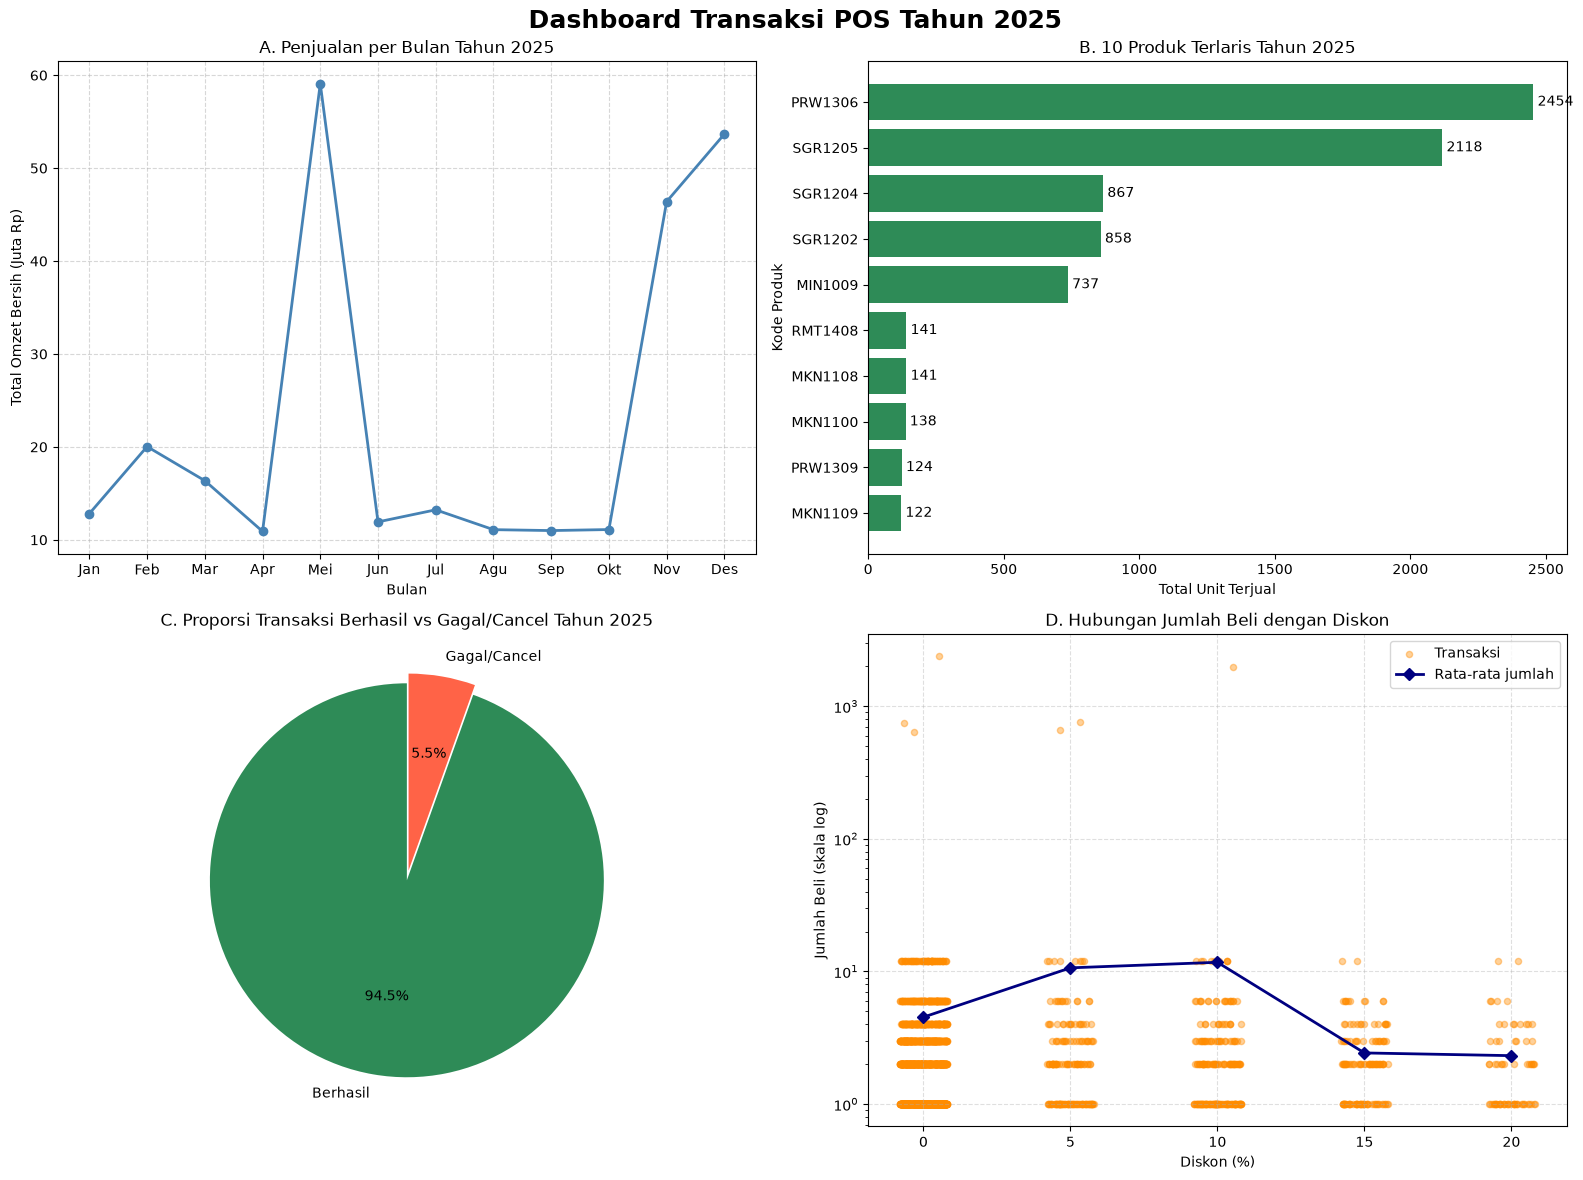

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Dashboard Transaksi POS Tahun 2025', fontsize=18, fontweight='bold')

# A (kiri atas): penjualan per bulan
ax = axes[0, 0]
ax.plot(nama_bulan, penjualan_bulanan.values / 1e6, marker='o', color='steelblue', linewidth=2)
ax.set_title('A. Penjualan per Bulan Tahun 2025')
ax.set_xlabel('Bulan')
ax.set_ylabel('Total Omzet Bersih (Juta Rp)')
ax.grid(True, linestyle='--', alpha=0.5)

# B (kanan atas): 10 produk terlaris
ax = axes[0, 1]
bars = ax.barh(top10_produk.index, top10_produk.values, color='seagreen')
ax.bar_label(bars, padding=3)
ax.set_title('B. 10 Produk Terlaris Tahun 2025')
ax.set_xlabel('Total Unit Terjual')
ax.set_ylabel('Kode Produk')

# C (kiri bawah): proporsi berhasil vs gagal/cancel
ax = axes[1, 0]
ax.pie(proporsi.values, labels=proporsi.index, autopct='%1.1f%%',
       colors=['seagreen', 'tomato'], startangle=90, explode=[0, 0.05])
ax.set_title('C. Proporsi Transaksi Berhasil vs Gagal/Cancel Tahun 2025')

# D (kanan bawah): hubungan jumlah beli dengan diskon
ax = axes[1, 1]
ax.scatter(x_jitter, df_2025['jumlah'], alpha=0.4, color='darkorange', s=20, label='Transaksi')
ax.plot(rata_jumlah.index, rata_jumlah.values, color='navy', marker='D', linewidth=2, label='Rata-rata jumlah')
ax.set_yscale('log')
ax.set_xticks([0, 5, 10, 15, 20])
ax.set_title('D. Hubungan Jumlah Beli dengan Diskon')
ax.set_xlabel('Diskon (%)')
ax.set_ylabel('Jumlah Beli (skala log)')
ax.grid(True, linestyle='--', alpha=0.4)
ax.legend()

plt.tight_layout()
plt.show()

In [10]:
print('Bulan tertinggi:', nama_bulan[penjualan_bulanan.idxmax() - 1], '-> Rp', round(penjualan_bulanan.max() / 1e6, 2), 'juta')
print('Bulan terendah :', nama_bulan[penjualan_bulanan.idxmin() - 1], '-> Rp', round(penjualan_bulanan.min() / 1e6, 2), 'juta')
print(proporsi)
print(rata_jumlah.round(2))
print('Korelasi jumlah vs diskon:', round(df_2025['jumlah'].corr(df_2025['diskon_persen']), 3))

Bulan tertinggi: Mei -> Rp 59.09 juta
Bulan terendah : Apr -> Rp 10.91 juta
status
Berhasil        2385
Gagal/Cancel     138
Name: count, dtype: int64
diskon_persen
0      4.53
5     10.66
10    11.73
15     2.43
20     2.32
Name: jumlah, dtype: float64
Korelasi jumlah vs diskon: 0.009
